# 02 — Dimensionality Reduction: PCA, SVD, t-SNE, UMAP

**Overview:** PCA and SVD (linear) vs t-SNE/UMAP (non-linear, visualization-focused) on the
`digits` dataset (8x8 images of handwritten digits, 64 features).

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`, `umap-learn` (optional — skips
gracefully if not installed).

```
!pip install -q umap-learn
```

Connects to: `01_clustering.ipynb` (2D visualization makes cluster structure visible) and Day
1's `05_ml_mathematics` (eigendecomposition/SVD, now via `sklearn.decomposition.PCA`'s
production implementation). Leads to: `10_ml_optimization`.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **PCA** | Principal Component Analysis | Linear dimensionality reduction: projects data onto orthogonal directions of maximum variance. |
| **SVD** | Singular Value Decomposition | Factorises a matrix as U·Σ·Vᵀ; basis for low-rank approximation and PCA. |
| **t-SNE** | t-distributed Stochastic Neighbor Embedding | Non-linear 2D/3D embedding that preserves local neighbourhoods; for visualisation only. |
| **UMAP** | Uniform Manifold Approximation and Projection | Non-linear dimensionality reduction; faster than t-SNE and keeps more global structure. |
| **API** | Application Programming Interface | The set of functions/classes a library exposes for you to call. |
| **ARI** | Adjusted Rand Index | Agreement between clusters and true labels, corrected for chance (1 = perfect, ~0 = random). |

In [ ]:
%pip install -q umap-learn

## 0. Environment & data

X shape: (1797, 64) (1797 images, 64 pixel features each)
y shape: (1797,) classes: [0 1 2 3 4 5 6 7 8 9]


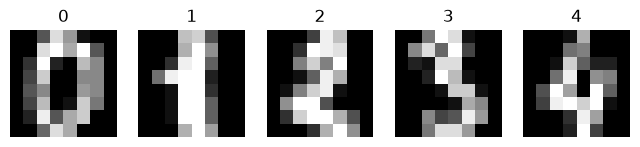

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

digits = load_digits()
X, y = digits.data, digits.target
print("X shape:", X.shape, "(1797 images, 64 pixel features each)")
print("y shape:", y.shape, "classes:", np.unique(y))

fig, axes = plt.subplots(1, 5, figsize=(8, 2))
for ax, img, label in zip(axes, digits.images[:5], y[:5]):
    ax.imshow(img, cmap="gray"); ax.set_title(str(label)); ax.axis("off")
plt.show()


## 1. PCA: linear dimensionality reduction

💡 **Intuition:** project the 64-dimensional pixel data onto the directions of maximum variance
— exactly the eigendecomposition-of-covariance idea from Day 1's `05_ml_mathematics`, now via
scikit-learn's production implementation (which uses SVD internally for numerical stability).

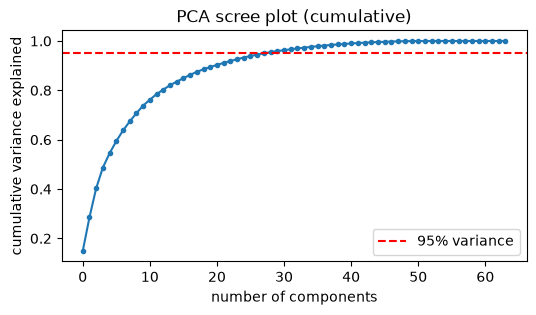

components needed for 95% variance: 29 (down from 64 original features)


In [2]:
pca_full = PCA().fit(X)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(cumulative_variance, marker=".")
ax.axhline(0.95, color="red", linestyle="--", label="95% variance")
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative variance explained")
ax.set_title("PCA scree plot (cumulative)")
ax.legend()
plt.show()

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"components needed for 95% variance: {n_components_95} (down from {X.shape[1]} original features)")
assert n_components_95 < X.shape[1]


## 2. PCA to 2D for visualization

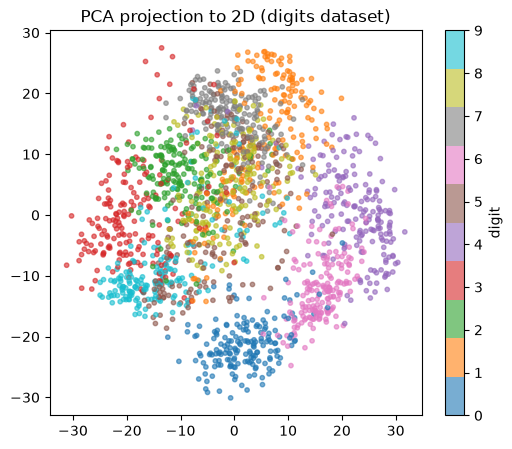

Note: digit clusters are only partially separated -- PCA keeps GLOBAL variance, which doesn't always align with what best separates the classes visually.


In [3]:
pca_2d = PCA(n_components=2).fit_transform(X)

fig, ax = plt.subplots(figsize=(6, 5))
scatter = ax.scatter(pca_2d[:, 0], pca_2d[:, 1], c=y, cmap="tab10", alpha=0.6, s=10)
ax.set_title("PCA projection to 2D (digits dataset)")
plt.colorbar(scatter, label="digit")
plt.show()

print("Note: digit clusters are only partially separated -- PCA keeps GLOBAL variance, "
      "which doesn't always align with what best separates the classes visually.")


## 3. SVD underneath PCA

💡 **Key Idea:** `sklearn.decomposition.PCA` computes its components via SVD of the (centered)
data matrix, not by explicitly forming and eigendecomposing the covariance matrix — more
numerically stable, same underlying idea from `05_ml_mathematics`.

In [4]:
X_centered = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

# The top 2 right-singular-vectors (rows of Vt) should match PCA's top 2 components up to sign.
manual_pca_2d = X_centered @ Vt[:2].T

# Compare magnitudes (sign of a component is arbitrary, so compare via correlation, not equality).
corr_0 = np.corrcoef(pca_2d[:, 0], manual_pca_2d[:, 0])[0, 1]
corr_1 = np.corrcoef(pca_2d[:, 1], manual_pca_2d[:, 1])[0, 1]
print(f"correlation between sklearn PCA and manual SVD projection, component 1: {abs(corr_0):.4f}")
print(f"correlation between sklearn PCA and manual SVD projection, component 2: {abs(corr_1):.4f}")

assert abs(corr_0) > 0.99
assert abs(corr_1) > 0.99


correlation between sklearn PCA and manual SVD projection, component 1: 1.0000
correlation between sklearn PCA and manual SVD projection, component 2: 1.0000


## 4. t-SNE: non-linear, local-structure-preserving visualization

⚠️ **Common Mistake:** using t-SNE output as features for a downstream model. t-SNE optimizes
for *local* neighborhood preservation at the cost of global distances — a point being close to
another in t-SNE space doesn't reliably mean they're similar overall, and re-running t-SNE with
a different seed can produce a visually different (though often still informative) layout.

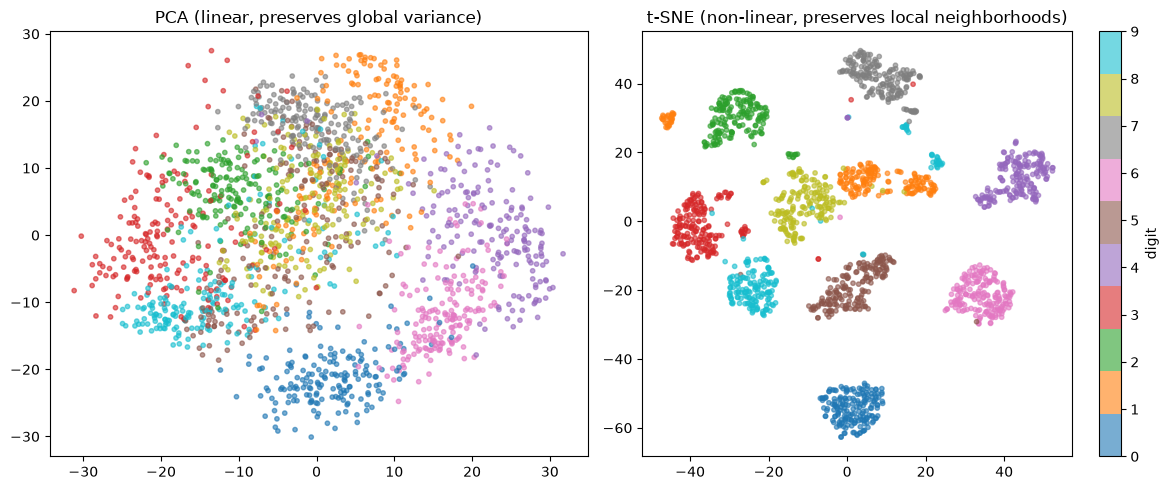

t-SNE typically separates the 10 digit classes into much tighter, more distinct clusters than PCA -- this is exactly why it's popular for visualization, and exactly why its distances shouldn't be trusted as globally meaningful.


In [5]:
tsne_2d = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(pca_2d[:, 0], pca_2d[:, 1], c=y, cmap="tab10", alpha=0.6, s=10)
axes[0].set_title("PCA (linear, preserves global variance)")
sc = axes[1].scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=y, cmap="tab10", alpha=0.6, s=10)
axes[1].set_title("t-SNE (non-linear, preserves local neighborhoods)")
plt.colorbar(sc, ax=axes[1], label="digit")
plt.tight_layout(); plt.show()

print("t-SNE typically separates the 10 digit classes into much tighter, more distinct "
      "clusters than PCA -- this is exactly why it's popular for visualization, and exactly "
      "why its distances shouldn't be trusted as globally meaningful.")


## 5. UMAP (if available)

💡 **Intuition:** similar motivation to t-SNE (local structure, visualization), but generally faster and better at preserving some global structure too.

/Users/USER/aiprojects/llm-fine-tuning/.venv312/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


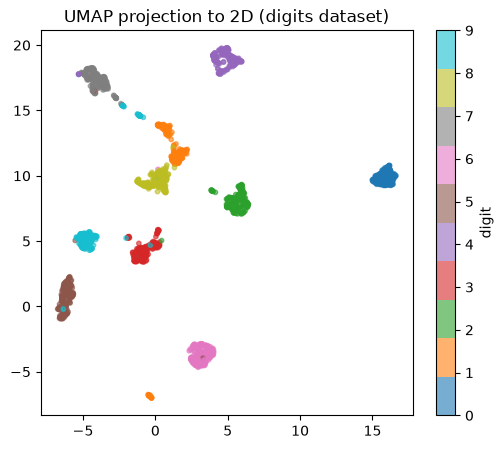

In [6]:
try:
    import umap
    umap_2d = umap.UMAP(n_components=2, random_state=42).fit_transform(X)

    fig, ax = plt.subplots(figsize=(6, 5))
    sc = ax.scatter(umap_2d[:, 0], umap_2d[:, 1], c=y, cmap="tab10", alpha=0.6, s=10)
    ax.set_title("UMAP projection to 2D (digits dataset)")
    plt.colorbar(sc, label="digit")
    plt.show()
except ImportError as e:
    print(f"Skipping UMAP in this environment (not installed): {e}")
    print("Install with `pip install umap-learn` -- the API mirrors t-SNE's "
          "`fit_transform`, so the rest of this notebook's logic applies unchanged.")


## 6. Connection to what's next

PCA's variance-maximizing projections reduce dimensionality in a way that's safe to feed into a
downstream model (e.g. before `10_ml_optimization`'s algorithms, or to speed up `01_clustering.ipynb`'s
K-means on high-dimensional data); t-SNE/UMAP are for human eyes only.

## 7. Interview questions
1. Why is it unsafe to use t-SNE's 2D output as input features for a classifier?
2. What's the relationship between PCA and SVD?
3. How would you decide how many PCA components to keep?
4. Why might two different runs of t-SNE (different random seeds) produce visually different layouts for the same data?
5. What's the main practical advantage of UMAP over t-SNE, in general?

## 8. Exercises
1. Run K-means (from `01_clustering.ipynb`) on the digits data reduced to 2D via PCA vs the raw 64D data, and compare cluster quality (ARI against true labels).
2. Vary t-SNE's `perplexity` parameter (5, 30, 100) and observe how the 2D layout changes.
3. Reduce the digits dataset to the number of components needed for 95% variance (from section 1) and re-fit a simple classifier — compare accuracy and training time to using all 64 features.

## 9. Summary

✅ PCA/SVD are linear, variance-preserving, and safe as a preprocessing step; t-SNE/UMAP are
non-linear, locally-focused, and meant for visualization only. This closes
`09_unsupervised_learning` — next: `10_ml_optimization`.